In [8]:
import time
import numpy as np
import pandas as pd
import tabulate
from incremental_dbscan import IncrementalDBSCAN, adjusted_rand_index, evaluate_clustering, prepare_features
from sklearn.cluster  import DBSCAN, HDBSCAN, KMeans, MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score


class BenchmarkPipeline:
    def __init__(self, data, num_batches =5, times=30):
        # Lưu tham số
        self.data = data
        self.num_batches = num_batches
        self.times = times
        self.raw_results = []

        # Chia data
        self.batches = self.prepare_stream()

    def prepare_stream(self):
        N = len(self.data)
        b1_size = int(0.7 * N)  # Lấy 70%
        batches = [ self.data[0 : b1_size] ]

        N_rest = self.num_batches - 1
        rem_size = N - b1_size
        step = rem_size // N_rest

        start = b1_size
        for i in range(N_rest):
            if i == (N_rest - 1): #Nếu là đợt cuối lấy data thì vét hết
                end = N
            else:
                end = start + step

            batches.append( self.data[start : end] )
            start = end

        return batches


    def run(self):
        def measure_time(func, data, run_type):
            start_time = time.perf_counter()
            if run_type == "batch":
                label = func.fit_predict(data)
            elif run_type == "partial":
                func.partial_fit(data)
                label = func.labels_
            end_time = time.perf_counter()
            return end_time - start_time, label

        for i in range(self.times):
            # Khởi tạo các model
            static_method = {
                "DBSCAN": DBSCAN(eps=0.65, min_samples=12),
                "HDBSCAN": HDBSCAN(min_cluster_size=12),
                "KMeans": KMeans(n_clusters=16, n_init=10, random_state=42),
                "HAC": AgglomerativeClustering(n_clusters=16)
            }
            inc_dbscan = IncrementalDBSCAN(eps=0.65, min_samples=12)
            minibatch = MiniBatchKMeans(n_clusters=16, n_init=10, random_state=42)

            accumulated_data = None

            for j, batch in enumerate(self.batches):
                step_log = {"Run_ID": i, "Batch_Index": j}
                accumulated_data = np.concatenate((accumulated_data, batch)) if accumulated_data is not None else batch

                batch_labels = {} # Dictionary chứa nhãn của thuật toán

                # Đo thời gian model Tĩnh
                for method_name, method in static_method.items():
                    t, lbl = measure_time(method, accumulated_data, "batch")
                    step_log[f"Time_{method_name}"] = t
                    batch_labels[method_name] = lbl

                # Đo thời gian model Luồng
                t_mini, _ = measure_time(minibatch, batch, "partial")
                step_log["Time_MiniBatch"] = t_mini
                batch_labels["MiniBatch"] = minibatch.predict(accumulated_data)

                t_inc, lbl_inc = measure_time(inc_dbscan, batch, "partial")
                step_log["Time_IncDBSCAN"] = t_inc
                batch_labels["IncDBSCAN"] = lbl_inc

                ground_truth = batch_labels["DBSCAN"]

                for name, lbl in batch_labels.items():
                    # Quét Silhouette và Noise
                    metrics = evaluate_clustering(accumulated_data, lbl)
                    step_log[f"Sil_{name}"] = metrics["silhouette"]
                    step_log[f"Davies_{name}"] = metrics["davies_bouldin"]
                    step_log[f"Calinski_{name}"] = metrics["calinski_harabasz"]

                    # Chỉ họ DBSCAN mới có điểm nhiễu (Noise)
                    if name in ["DBSCAN", "HDBSCAN", "IncDBSCAN"]:
                        step_log[f"Noise_{name}"] = metrics["noise_ratio"]

                    # Tính ARI so với mốc DBSCAN gốc (Bỏ qua chính nó)
                    if name != "DBSCAN":
                        step_log[f"ARI_{name}"] = adjusted_rand_index(ground_truth, lbl)

                self.raw_results.append(step_log)

    def report(self):
        if not self.raw_results:
            return pd.DataFrame(), pd.DataFrame()

        df = pd.DataFrame(self.raw_results)
        grouped = df.groupby("Batch_Index")

        time_cols = [c for c in df.columns if c.startswith("Time_")]
        time_agg = {c: ["mean", "std"] for c in time_cols}
        time_df = grouped.agg(time_agg)
        time_df.columns = [f"{col[0]}_{col[1]}" for col in time_df.columns]

        qual_cols = [c for c in df.columns if c.startswith(("Sil_", "Noise_", "ARI_", "Davies_", "Calinski_"))]
        qual_agg = {c: ["mean"] for c in qual_cols}
        qual_df = grouped.agg(qual_agg)
        qual_df.columns = [f"{col[0]}_{col[1]}" for col in qual_df.columns]

        return time_df.reset_index(), qual_df.reset_index()

In [9]:
# Chạy benchmark 30 lần, mỗi lần 4 batch (70-10-10-10)
df = pd.read_excel("sku_clean_scaled.xlsx").sort_values('Stream_order').reset_index(drop=True)
data = prepare_features(df)
pipeline = BenchmarkPipeline(data, num_batches=4, times=30)
pipeline.run()
final_df = pipeline.report()
time_df, qual_df = pipeline.report()

#Lưu kết quả
with pd.ExcelWriter("benchmark_results.xlsx") as writer:
    time_df.to_excel(writer, sheet_name="Time_Report", index=False)
    qual_df.to_excel(writer, sheet_name="Quality_Report", index=False)

# In kết quả
print(tabulate.tabulate(time_df, headers="keys", tablefmt="psql"))
print(tabulate.tabulate(qual_df, headers="keys", tablefmt="psql"))

+----+---------------+--------------------+-------------------+---------------------+--------------------+--------------------+-------------------+-----------------+----------------+-----------------------+----------------------+-----------------------+----------------------+
|    |   Batch_Index |   Time_DBSCAN_mean |   Time_DBSCAN_std |   Time_HDBSCAN_mean |   Time_HDBSCAN_std |   Time_KMeans_mean |   Time_KMeans_std |   Time_HAC_mean |   Time_HAC_std |   Time_MiniBatch_mean |   Time_MiniBatch_std |   Time_IncDBSCAN_mean |   Time_IncDBSCAN_std |
|----+---------------+--------------------+-------------------+---------------------+--------------------+--------------------+-------------------+-----------------+----------------+-----------------------+----------------------+-----------------------+----------------------|
|  0 |             0 |          0.0550335 |         0.0133495 |           0.0707816 |         0.00874346 |          0.0765728 |         0.0172661 |       0.0757902 |    

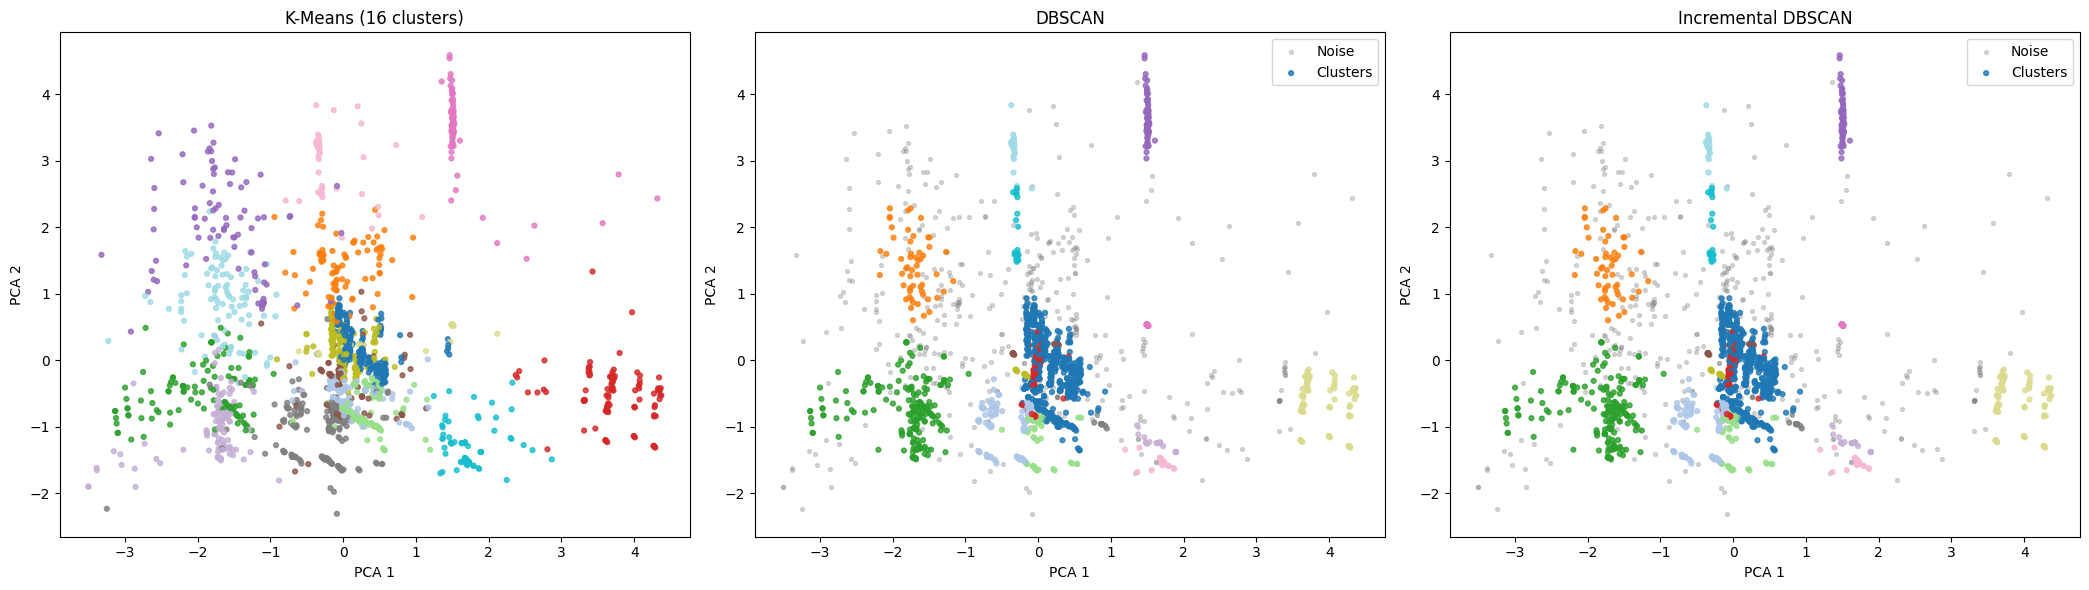

In [4]:
# VẼ ĐỒ THỊ TRỰC QUAN 2 CHIỀU
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from incremental_dbscan import IncrementalDBSCAN, prepare_features

df = pd.read_excel("sku_clean_scaled.xlsx").sort_values('Stream_order').reset_index(drop=True)
X = prepare_features(df)
# Dùng PCA 2 chiều
X_pca = PCA(n_components=2).fit_transform(X)

x_coord = X_pca[:, 0]
y_coord = X_pca[:, 1]

# Phân cụm trên dữ liệu X gốc
labels_kmeans = KMeans(n_clusters=16, n_init=10, random_state=42).fit_predict(X)
labels_dbscan = DBSCAN(eps=0.65, min_samples=12).fit_predict(X)
labels_incre = IncrementalDBSCAN(eps=0.65, min_samples=12).fit_predict(X)



def plot_density(ax, x, y, labels, title):
    # Tách index điểm nhiễu và điểm thuộc cụm
    noise_idx = np.where(labels == -1)[0]
    cluster_idx = np.where(labels >= 0)[0]

    # Vẽ nhiễu
    ax.scatter(x[noise_idx], y[noise_idx], c="gray", alpha=0.3, s=8, label="Noise", zorder=1)

    # Vẽ cụm
    if len(cluster_idx) > 0:
        scatter = ax.scatter( x[cluster_idx], y[cluster_idx], c=labels[cluster_idx],
                             cmap="tab20", alpha=0.8, s=12, label="Clusters", zorder=2 )

    ax.set_title(title)
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(loc="best")


fig, axes = plt.subplots( 1, 3, figsize=(21, 6))

# K-Means
axes[0].scatter( x_coord, y_coord, c=labels_kmeans, cmap="tab20", s=12, alpha=0.8)
axes[0].set_title("K-Means (16 clusters)")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

# DBSCAN
plot_density( axes[1], x_coord, y_coord, labels_dbscan,"DBSCAN")

# Incremental DBSCAN
plot_density( axes[2], x_coord, y_coord, labels_incre, "Incremental DBSCAN")

plt.tight_layout()
plt.show()

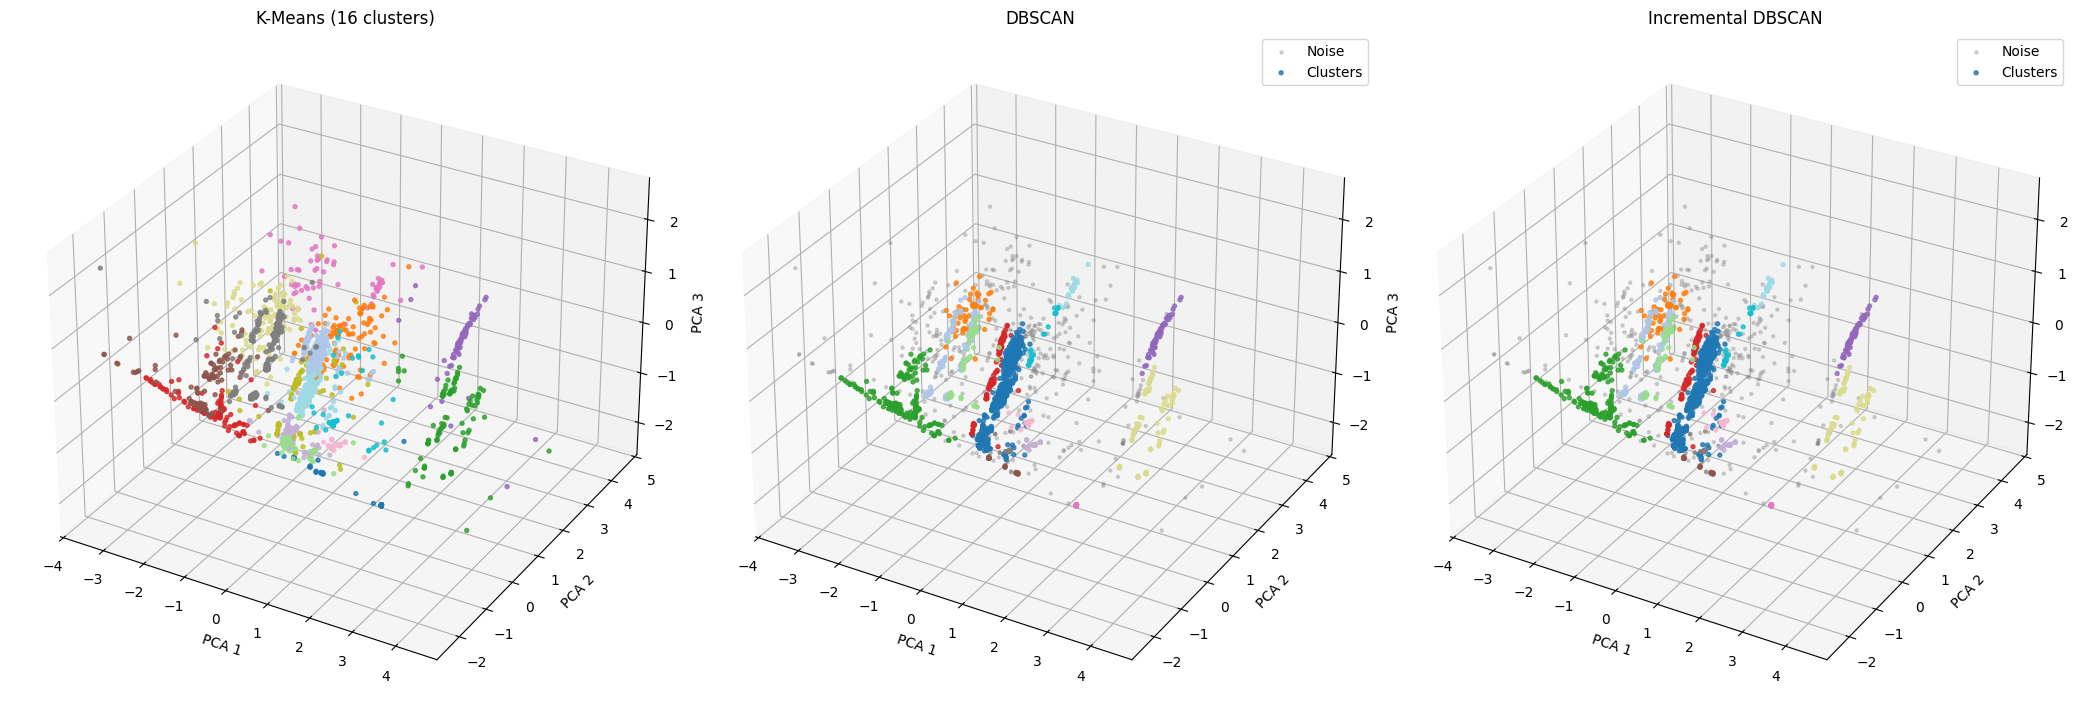

In [5]:
# VẼ ĐỒ THỊ TRỰC QUAN 3 CHIỀU
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from incremental_dbscan import IncrementalDBSCAN

#PCA 3 chiều và chuẩn bị nhãn

X_pca = PCA(n_components=3).fit_transform(X)

x_coord = X_pca[:, 0]
y_coord = X_pca[:, 1]
z_coord = X_pca[:, 2]

# Phân cụm trên dữ liệu X gốc
labels_kmeans = KMeans(n_clusters=16, random_state=42, n_init="auto").fit_predict(X)

labels_dbscan = DBSCAN(eps=0.65, min_samples=12).fit_predict(X)

labels_incre = IncrementalDBSCAN( eps=0.65, min_samples=12).fit_predict(X)


# Hàm vẽ các cụm và điểm nhiễu trong 3D

def plot_density_3d(ax, x, y, z, labels, title):

    # Tách điểm nhiễu và điểm thuộc cụm
    noise_idx = np.where(labels == -1)[0]
    cluster_idx = np.where(labels >= 0)[0]

    #Vẽ nhiễu
    ax.scatter( x[noise_idx], y[noise_idx], z[noise_idx], c="gray", alpha=0.3, s=5, label="Noise")

    #Vẽ các cụm lên trên
    if len(cluster_idx) > 0:
        ax.scatter(x[cluster_idx], y[cluster_idx], z[cluster_idx],
                   c=labels[cluster_idx], cmap="tab20", alpha=0.8, s=8, label="Clusters")

    ax.set_title(title)
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.set_zlabel("PCA 3")
    ax.legend(loc="best")


# Khởi tạo khung

fig = plt.figure(figsize=(21, 7))

# Khung 1: K-Means
ax1 = fig.add_subplot(1, 3, 1, projection="3d")

ax1.scatter( x_coord, y_coord, z_coord,
            c=labels_kmeans, cmap="tab20", s=8, alpha=0.8)

ax1.set_title("K-Means (16 clusters)")
ax1.set_xlabel("PCA 1")
ax1.set_ylabel("PCA 2")
ax1.set_zlabel("PCA 3")


# Khung 2: DBSCAN
ax2 = fig.add_subplot(1, 3, 2, projection="3d")

plot_density_3d( ax2, x_coord, y_coord, z_coord, labels_dbscan, "DBSCAN")


# Khung 3: Incremental DBSCAN
ax3 = fig.add_subplot(1, 3, 3, projection="3d")

plot_density_3d( ax3, x_coord, y_coord, z_coord, labels_incre, "Incremental DBSCAN")


plt.tight_layout()
plt.show()